# SaaS subscription metrics: MRR, churn, cohorts and lifetime value
**Business question:** how healthy is a subscription business? Monthly and annual plans (10,497 subscriptions, 2011-2014) are turned into the KPIs a CFO or investor asks for: **MRR, new vs churned MRR, logo churn, cohort retention and LTV**.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
s = pd.read_csv("data/subscriptions.csv", parse_dates=["start_date", "end_date"])
s["mrr"] = np.where(s.subscription_period == "annual", s.price / 12, s.price)       # normalise annual plans to monthly revenue
print(s.subscription_period.value_counts().to_string()); s.head()

subscription_period
annual     6245
monthly    4252


,id,customer_id,end_date,start_date,subscription_period,price,mrr
0,5,1337,2014-12-28 01:40:57,2014-10-25 12:39:18,monthly,50,50.000000
1,28,1338,2014-11-19 01:48:05,2014-10-17 13:47:59,monthly,50,50.000000
2,44,1339,2014-11-01 20:56:37,2014-10-30 05:50:54,annual,500,41.666667
3,85,1340,2014-12-09 02:51:57,2013-12-05 14:51:57,annual,500,41.666667
4,168,1341,2015-11-16 09:19:29,2014-11-13 20:19:23,annual,500,41.666667


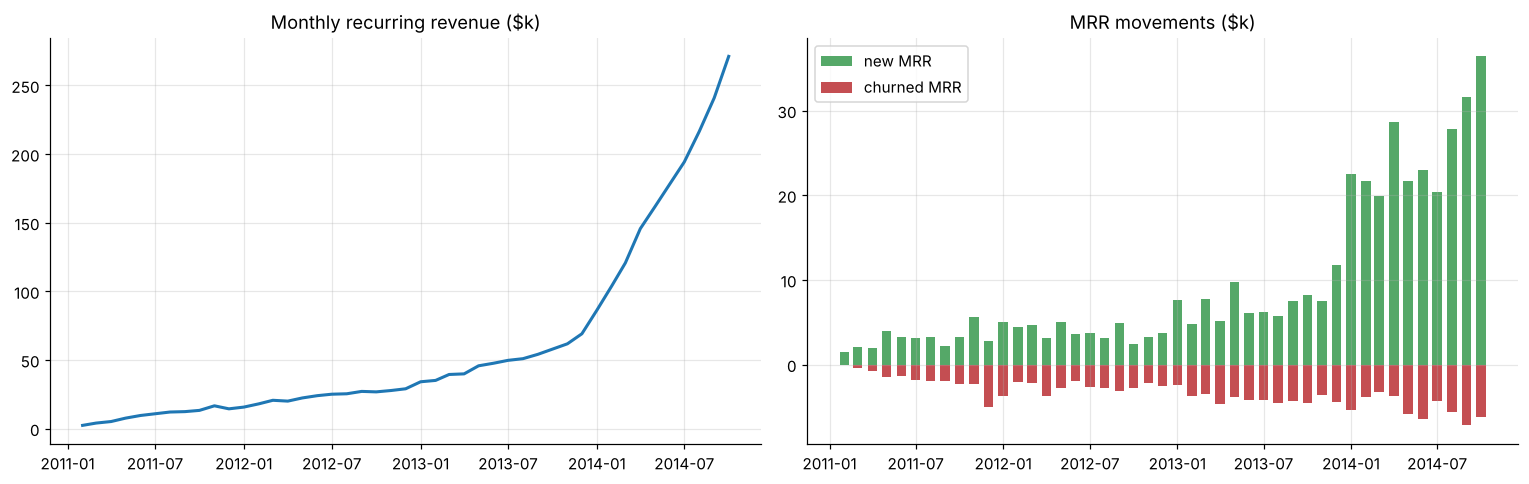

,active subs,MRR,new MRR,churned MRR,logo churn rate
month,,,,,
2014-05-01,3751,161508.333,21725.000,5866.667,0.036
2014-06-01,4150,178158.333,23033.333,6383.333,0.035
2014-07-01,4521,194233.333,20375.000,4300.000,0.021
2014-08-01,5038,216450.000,27775.000,5558.333,0.025
2014-09-01,5599,240916.667,31658.333,7191.667,0.030
2014-10-01,6290,271175.000,36408.333,6150.000,0.023


In [2]:
months = pd.period_range(s.start_date.min().to_period("M"), s.start_date.max().to_period("M"), freq="M")   # up to the last month with sign-ups
rows = []
for m in months:
    m_start, m_end = m.start_time, m.end_time
    active = s[(s.start_date <= m_end) & (s.end_date > m_end)]
    new = s[(s.start_date >= m_start) & (s.start_date <= m_end)]
    churned = s[(s.end_date >= m_start) & (s.end_date <= m_end)]
    rows.append({"month": m.to_timestamp(), "active subs": len(active), "MRR": active.mrr.sum(), "new MRR": new.mrr.sum(),
                 "churned MRR": churned.mrr.sum(), "new subs": len(new), "churned subs": len(churned)})
k = pd.DataFrame(rows).set_index("month")
k["logo churn rate"] = k["churned subs"] / k["active subs"].shift(1)
k = k.iloc[1:-1]                                   # drop partial first/last months
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(k.index, k.MRR / 1000, lw=2); ax[0].set_title("Monthly recurring revenue ($k)")
ax[1].bar(k.index, k["new MRR"] / 1000, width=20, color="#55A868", label="new MRR"); ax[1].bar(k.index, -k["churned MRR"] / 1000, width=20, color="#C44E52", label="churned MRR")
ax[1].set_title("MRR movements ($k)"); ax[1].legend()
fig.tight_layout(); plt.savefig(IMG / "mrr.png", bbox_inches="tight"); plt.show()
k[["active subs", "MRR", "new MRR", "churned MRR", "logo churn rate"]].tail(6).round(3)

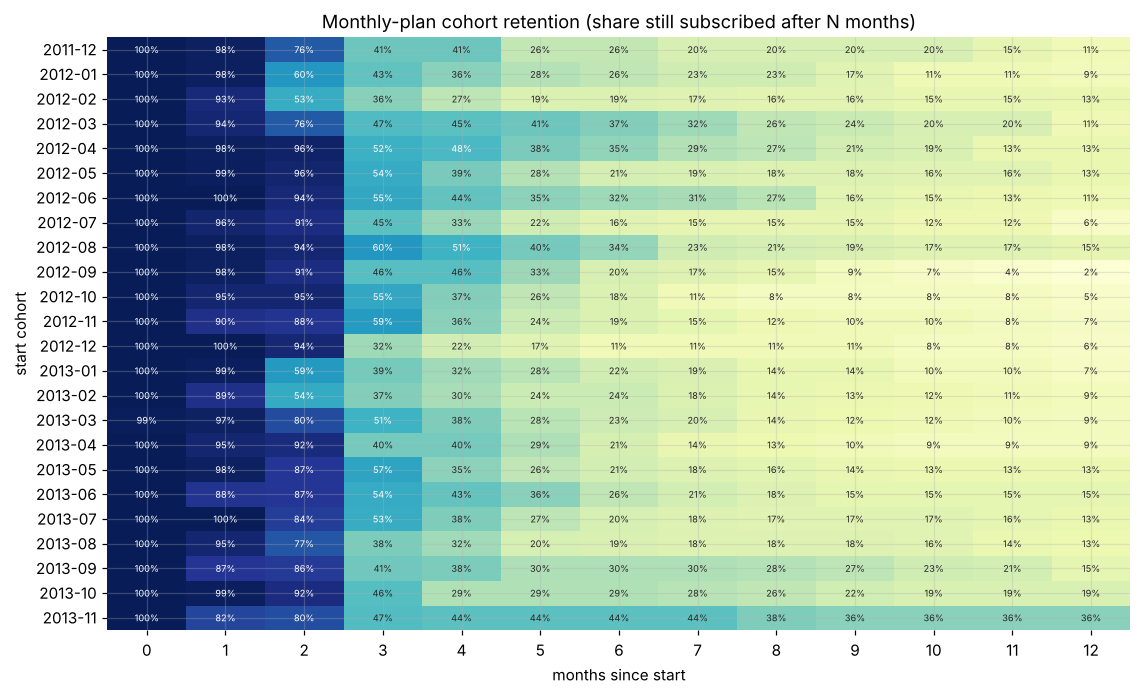

In [3]:
s["cohort"] = s.start_date.dt.to_period("M")
s["life_m"] = ((s.end_date - s.start_date).dt.days / 30.44)
coh = pd.DataFrame({m: (s.life_m > m).groupby(s.cohort).mean() for m in range(0, 25)})
monthly = s[s.subscription_period == "monthly"]
coh_m = pd.DataFrame({m: (monthly.life_m > m).groupby(monthly.cohort).mean() for m in range(0, 13)})
coh_m = coh_m[coh_m.index <= monthly.cohort.max() - 12]
plt.figure(figsize=(12, 7))
sns.heatmap(coh_m.iloc[-24:], cmap="YlGnBu", vmin=0, vmax=1, annot=True, fmt=".0%", annot_kws={"size": 6}, cbar=False)
plt.title("Monthly-plan cohort retention (share still subscribed after N months)"); plt.xlabel("months since start"); plt.ylabel("start cohort")
plt.savefig(IMG / "cohorts.png", bbox_inches="tight"); plt.show()

In [4]:
summary = s.groupby("subscription_period").agg(subs=("id", "size"), price=("price", "first"), mrr=("mrr", "first"),
                                               median_life_months=("life_m", "median"), mean_life_months=("life_m", "mean"))
summary["LTV (mean life x MRR)"] = summary.mean_life_months * summary.mrr
summary.round(1)

,subs,price,mrr,median_life_months,mean_life_months,LTV (mean life x MRR)
subscription_period,,,,,,
annual,6245,500,41.7,12.1,14.3,595.9
monthly,4252,50,50.0,2.1,4.2,209.1


**Findings**
* MRR grew to about **$271k by October 2014**, with new MRR outpacing churned MRR roughly **5 to 1** and monthly logo churn of only about **2-4%**. Growth is acquisition-led and healthy. The early-warning sign to monitor is churned MRR catching up with new MRR.
* Monthly-plan cohorts keep almost everyone through the **initial ~2-month term**, then **about half leave at month 3**, and retention flattens to 10-20% after a year. The first renewal decision is the critical moment for onboarding and engagement campaigns.
* Annual plans stay much longer and carry higher LTV, so steering customers to annual billing (for example with a discount) is a strong lever, provided the discount is smaller than the LTV uplift.